# Notebook 6. ¿Y si el PDF es un escaneo? OCR

**Duración prevista en clase: 1 h** · **Dificultad: media**

Hasta ahora, Docling leía la capa de texto que trae el PDF. Un PDF escaneado (una fotocopia, una foto con el
móvil) no tiene capa de texto: cada página es una imagen. Para indexarlo, primero hay que pasar de la imagen al
texto: **OCR** (*Optical Character Recognition*).

Objetivo: simular el escaneo de dos páginas de nuestro PDF y leerlo con tres herramientas, de la más clásica a la
más moderna, usando el PDF digital como referencia para medir.

| Herramienta | Qué es | Dónde corre |
|---|---|---|
| RapidOCR | OCR en dos etapas: una red detecta las líneas y otra lee cada una | CPU, local |
| Docling con OCR | Análisis de la maquetación + RapidOCR: devuelve Markdown con tablas | Local |
| VLM por API (`VLM_MODEL`) | Un modelo de visión y lenguaje lee la página entera | OpenRouter |

Para seguir con más motores (Tesseract, EasyOCR, TrOCR, VLMs locales como GOT-OCR2 o DeepSeek-OCR) y otros
documentos (manuscritos, tickets), está el laboratorio completo en `semana2-alternativa/ocr/`.

Referencias:
- RapidOCR: https://github.com/RapidAI/RapidOCR
- Docling: https://docling-project.github.io/docling/

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada


Trazas:      jsonl /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/trazas/trazas.jsonl  (alumno: profesor)


/home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/rag_lab/tracing.py:49: UserWarning: No se pudo conectar con Langfuse ([Errno 111] Connection refused): las trazas se guardan en JSONL.
  warnings.warn(f"No se pudo conectar con Langfuse ({e}): las trazas se guardan en JSONL.")


## 1. Un PDF escaneado

Simulamos el escaneo de la página 3 (texto) y la 13 (texto y la tabla de participación por fase): renderizamos la
página como imagen, la pasamos a gris, la giramos un poco, le añadimos ruido y la comprimimos en JPEG, como haría
un escáner barato. Después guardamos las dos imágenes como un PDF que solo contiene imágenes.

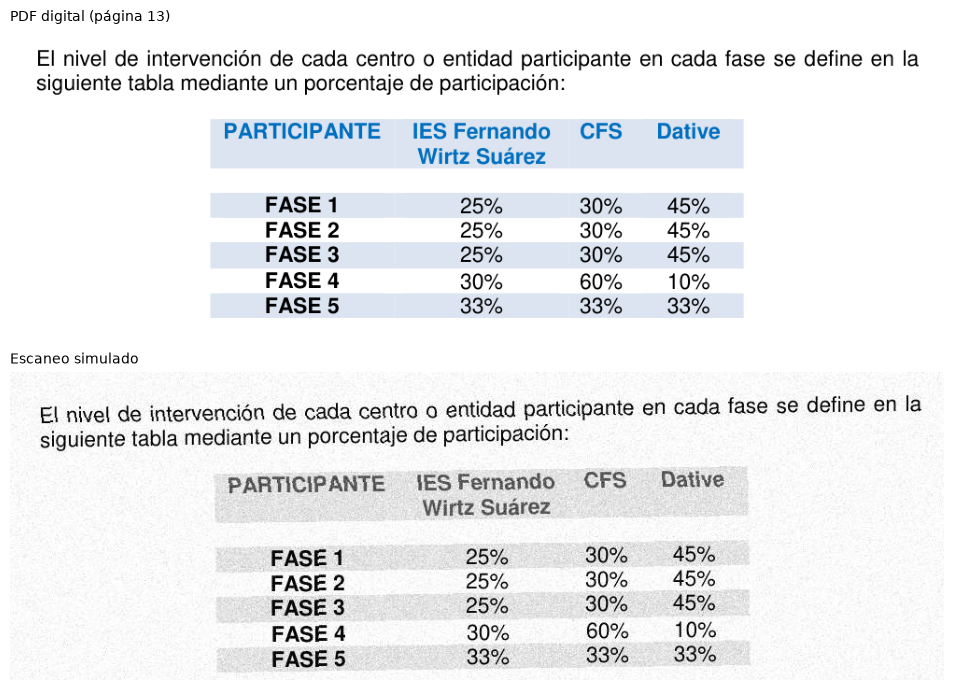

In [2]:
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from rag_lab import pdf

PAGES = [3, 13]

def scan(image, angle=0.8, noise=12, quality=60, seed=0):
    """Imita un escaneo: gris, un poco girado, con ruido y comprimido en JPEG."""
    rng = np.random.default_rng(seed)
    gray = image.convert("L").rotate(angle, expand=True, fillcolor=255)
    pixels = np.array(gray, dtype=np.int16) + rng.normal(0, noise, gray.size[::-1]).astype(np.int16)
    buffer = io.BytesIO()
    Image.fromarray(pixels.clip(0, 255).astype(np.uint8)).save(buffer, "JPEG", quality=quality)
    return Image.open(buffer).convert("RGB")

images = pdf.render_pages(dpi=150)
scans = {n: scan(Image.open(images[n])) for n in PAGES}
scanned_pdf = CFG.DOC_CACHE / "escaneado.pdf"
scans[PAGES[0]].save(scanned_pdf, save_all=True, append_images=[scans[n] for n in PAGES[1:]], resolution=150)

box = (120, 160, 1120, 490)  # recorte con la tabla de la página 13
fig, panels = plt.subplots(2, 1, figsize=(10, 7))
panels[0].imshow(Image.open(images[13]).crop(box))
panels[0].set_title("PDF digital (página 13)", loc="left", fontsize=10)
panels[1].imshow(scans[13].crop(box))
panels[1].set_title("Escaneo simulado", loc="left", fontsize=10)
for panel in panels:
    panel.axis("off")
plt.tight_layout()
plt.show()

In [3]:
import pymupdf

digital = pdf.raw_text_by_page()  # capa de texto del PDF original: será la referencia
with pymupdf.open(scanned_pdf) as scanned:
    for n, page in zip(PAGES, scanned):
        print(f"Página {n}: {len(digital[n])} caracteres en el PDF digital, {len(page.get_text())} en el escaneado")

Página 3: 3105 caracteres en el PDF digital, 0 en el escaneado
Página 13: 2468 caracteres en el PDF digital, 0 en el escaneado


El PDF escaneado no tiene ni un carácter de texto: para PyMuPDF está vacío, y un RAG no tendría nada que
indexar. Como sí tenemos el PDF digital, usamos su texto como **referencia** (*ground truth*) para medir cada OCR.

## 2. Cómo se mide un OCR

- **CER** (*Character Error Rate*): cuántos caracteres hay que cambiar, borrar o insertar para pasar del texto del
  OCR a la referencia (la distancia de edición o de Levenshtein), dividido entre los caracteres de la referencia.
- **WER** (*Word Error Rate*): lo mismo, contando palabras.
- **F1 de palabras**: compara qué palabras aparecen, **sin importar el orden** (bolsa de palabras).

Antes de medir normalizamos los dos textos (minúsculas, espacios y símbolos de Markdown), para no penalizar a quien
devuelve `## Título` frente a `Título`.

In [4]:
import re
import unicodedata
from collections import Counter

def normalize(text):
    text = unicodedata.normalize("NFC", text.lower())
    text = re.sub(r"[#*|_`>-]+", " ", text)  # símbolos de Markdown y separadores de tabla
    return " ".join(text.split())

def words(text):
    return re.findall(r"\w+", normalize(text))

def edit_distance(a, b):
    """Distancia de Levenshtein entre dos secuencias (de caracteres o de palabras)."""
    previous = list(range(len(b) + 1))
    for i, x in enumerate(a, start=1):
        current = [i]
        for j, y in enumerate(b, start=1):
            current.append(min(previous[j] + 1,              # borrar
                               current[j - 1] + 1,           # insertar
                               previous[j - 1] + (x != y)))  # sustituir (o nada si son iguales)
        previous = current
    return previous[-1]

def cer(reference, hypothesis):
    reference, hypothesis = normalize(reference), normalize(hypothesis)
    return edit_distance(reference, hypothesis) / max(len(reference), 1)

def wer(reference, hypothesis):
    reference, hypothesis = words(reference), words(hypothesis)
    return edit_distance(reference, hypothesis) / max(len(reference), 1)

def word_f1(reference, hypothesis):
    ref, hyp = Counter(words(reference)), Counter(words(hypothesis))
    common = sum((ref & hyp).values())
    if not common:
        return 0.0
    precision, recall = common / sum(hyp.values()), common / sum(ref.values())
    return 2 * precision * recall / (precision + recall)

ref = "El niño comió pan."
for hyp in ["El niño comió pan.", "El nino comio pan.", "pan. El niño comió", "El niño comió pan y luego durmió la siesta."]:
    print(f"{hyp!r:48} CER={cer(ref, hyp):.2f}  WER={wer(ref, hyp):.2f}  F1={word_f1(ref, hyp):.2f}")

'El niño comió pan.'                             CER=0.00  WER=0.00  F1=1.00
'El nino comio pan.'                             CER=0.11  WER=0.50  F1=0.50
'pan. El niño comió'                             CER=0.56  WER=0.50  F1=1.00
'El niño comió pan y luego durmió la siesta.'    CER=1.39  WER=1.25  F1=0.62


Fíjate en:
- **Sin tildes**: el CER apenas sube (2 caracteres), pero el WER se dispara (2 de 4 palabras). Un carácter mal
  leído estropea la palabra entera, y en un RAG, BM25 ya no la encuentra.
- **Orden cambiado**: CER y WER penalizan mucho; el F1 no se entera.
- **Texto añadido**: las inserciones también cuentan, y CER y WER pueden pasar de 1 (100 %).

## 3. OCR clásico en dos etapas: RapidOCR

RapidOCR empaqueta en ONNX los modelos de PaddleOCR y corre en CPU. Trabaja en dos etapas:
1. un **detector** encuentra las cajas donde hay texto;
2. un **reconocedor** lee cada caja como una línea.

Es el OCR que usa Docling por defecto. Devuelve el texto de cada caja, su posición y su confianza.

In [5]:
import logging
import time

from rapidocr import RapidOCR

logging.getLogger("RapidOCR").disabled = True  # sin mensajes en cada llamada
rapid = RapidOCR()

RESULTS, OUTPUTS = [], {}

def record(engine, n, text, seconds, cost_usd=0.0):
    """Guarda la salida de un motor para una página y sus métricas frente a la referencia."""
    OUTPUTS[(engine, n)] = text
    RESULTS.append({"motor": engine, "página": n, "CER": cer(digital[n], text), "WER": wer(digital[n], text),
                    "F1": word_f1(digital[n], text), "segundos": seconds, "coste_usd": cost_usd})

for n in PAGES:
    t0 = time.perf_counter()
    output = rapid(np.array(scans[n]))
    record("RapidOCR", n, "\n".join(output.txts), time.perf_counter() - t0)
pd.DataFrame(RESULTS).round(3)

,motor,página,CER,WER,F1,segundos,coste_usd
0,RapidOCR,3,0.081,0.081,0.949,7.069,0.0
1,RapidOCR,13,0.545,0.663,0.969,5.850,0.0


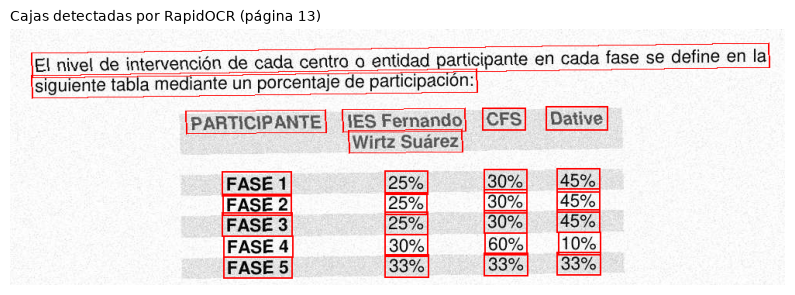

1.00  Financiado por
0.99  la Unión Europea
1.00  Plan de Recuperación,
0.98  Transformación y Resiliencia
1.00  NextGenerationEU
0.99  El nivel de intervención de cada centro o entidad participante en cada fase se define en la
1.00  siguiente tabla mediante un porcentaje de participación:
1.00  PARTICIPANTE
1.00  IES Fernando
1.00  CFS
1.00  Dative
0.96  Wirtz Suárez
0.97  FASE 1
1.00  25%


In [6]:
from PIL import ImageDraw

output = rapid(np.array(scans[13]))
boxed = scans[13].copy()
draw = ImageDraw.Draw(boxed)
for corners in output.boxes:
    draw.polygon([tuple(map(float, p)) for p in corners], outline="red", width=2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(boxed.crop(box))
ax.set_title("Cajas detectadas por RapidOCR (página 13)", loc="left", fontsize=10)
ax.axis("off")
plt.show()
for text, score in list(zip(output.txts, output.scores))[:14]:
    print(f"{score:.2f}  {text}")

Cada celda de la tabla es una caja suelta. RapidOCR lee bien las palabras, pero no sabe que forman una tabla:
el texto sale como una lista de celdas, igual que con PyMuPDF en el notebook 2. Además lee el texto del logo de la
cabecera ("Financiado por la Unión Europea"), que en el PDF digital es una imagen y no está en la referencia.

## 4. Docling con OCR

Docling no se limita a leer: primero analiza la **maquetación** (títulos, párrafos, tablas, figuras) y, donde no
hay capa de texto, llama a RapidOCR. El resultado es el mismo Markdown con tablas del notebook 2, así que el resto
del pipeline (chunking, índices y versiones) no cambia. La conversión tarda unos 40 segundos.

In [7]:
from docling.document_converter import DocumentConverter

logging.getLogger("docling").setLevel(logging.ERROR)
t0 = time.perf_counter()
scanned_doc = DocumentConverter().convert(scanned_pdf).document
seconds = (time.perf_counter() - t0) / len(PAGES)  # incluye la carga de los modelos
for i, n in enumerate(PAGES, start=1):
    record("Docling + OCR", n, scanned_doc.export_to_markdown(page_no=i), seconds)
docling_13 = OUTPUTS[("Docling + OCR", 13)]
print(docling_13[:900])
print("[...]")
print(next(line for line in docling_13.splitlines() if "NEA 1" in line.upper())[:170], "[...]")

<!-- image -->

<!-- image -->

| PARTICIPANTE   | IES Fernando Wirtz Suárez   | CFS   | Dative   |
|----------------|-----------------------------|-------|----------|
| FASE 1         | 25%                         | 30%   | 45%      |
| FASE 2         | 25%                         | 30%   | 45%      |
| FASE 3         | 25%                         | 30%   | 45%      |
| FASE 4         | 30%                         | 60%   | 10%      |
| FASE 5         | 33%                         | 33%   | 33%      |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:

<!-- image -->

## 5. RESULTADOS Y PRODUCTOS ESPERADOS POR LÍNEA DE ACTUACIÓN

|                                                                                         
[...]
| LiNEA 1: Innovación tecnológica y Transferencia de conocimiento entre empresas o entidades 

La tabla de participación vuelve a ser una tabla, y sin errores. Pero mira la última línea, de la tabla de la
sección 5:
- El OCR ha leído «LiNEA» donde pone «LÍNEA»: la Í mayúscula se ha convertido en una i. En un RAG estos errores
  importan: BM25 trata «linea» y «línea» como palabras distintas, así que una pregunta con tilde no encontraría
  ese fragmento.
- Docling repite la cabecera combinada «LÍNEA 1: ...» en cada columna de la tabla. Lo veremos en las métricas.

## 5. Un VLM lee la página

Un VLM (*Vision-Language Model*) no detecta cajas ni líneas. Parte la imagen en **parches** (por ejemplo, de
16 × 16 píxeles), convierte cada parche en un vector y se los pasa al modelo de lenguaje como si fueran tokens
de texto. Después genera la respuesta token a token, como cualquier LLM. Por eso puede devolver Markdown,
responder preguntas sobre la imagen... y también inventarse cosas (sección 8).

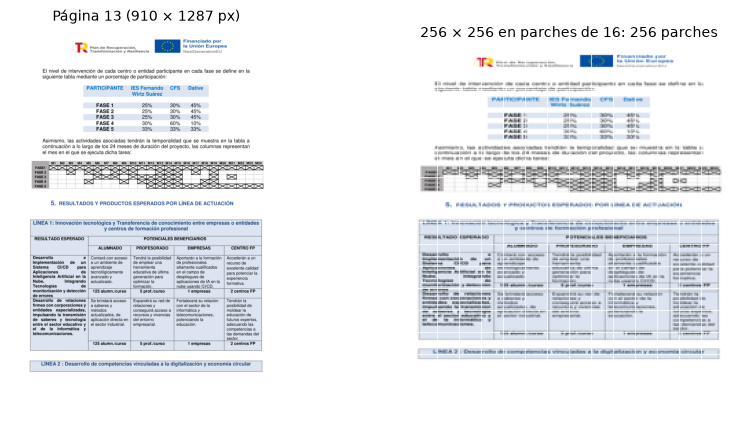

In [8]:
side, patch = 256, 16
page = Image.open(pdf.render_pages()[13]).convert("RGB")
resized = page.resize((side, side))

fig, panels = plt.subplots(1, 2, figsize=(10, 5))
panels[0].imshow(page)
panels[0].set_title(f"Página 13 ({page.size[0]} × {page.size[1]} px)", fontsize=10)
panels[1].imshow(resized)
for x in range(0, side + 1, patch):
    panels[1].axhline(x - 0.5, color="white", linewidth=0.5)
    panels[1].axvline(x - 0.5, color="white", linewidth=0.5)
panels[1].set_title(f"256 × 256 en parches de 16: {(side // patch) ** 2} parches", fontsize=10)
for panel in panels:
    panel.axis("off")
plt.show()

Más resolución quiere decir más parches. ¿Cobra el proveedor más tokens por ello? Comparamos la misma petición
sin imagen y con la página a dos resoluciones:

In [9]:
from rag_lab import llm

text = "Responde solo con la palabra: ok."
rows = []
text_only = llm.chat([{"role": "user", "content": text}], CFG.VLM_MODEL, max_tokens=5, step="tokens_imagen")
rows.append({"petición": "solo texto", "tokens de entrada": text_only.input_tokens, "coste_usd": text_only.cost_usd})
for dpi in (55, 110):
    path = pdf.render_pages(dpi=dpi)[13]
    r = llm.vision(text, [path], max_tokens=5, step="tokens_imagen")
    rows.append({"petición": f"texto + página a {dpi} ppp ({Image.open(path).size[0]} px de ancho)",
                  "tokens de entrada": r.input_tokens, "coste_usd": r.cost_usd})
pd.DataFrame(rows)

,petición,tokens de entrada,coste_usd
0,solo texto,9,0.000004
1,texto + página a 55 ppp (455 px de ancho),1101,0.000277
2,texto + página a 110 ppp (910 px de ancho),1101,0.000277


Con el `VLM_MODEL` de referencia (gemini-3.1-flash-lite), la imagen cuesta lo mismo a las dos resoluciones: este
modelo cobra una cantidad fija de tokens por imagen. Otros proveedores cobran según el tamaño de la imagen, y con
ellos bajar la resolución sí ahorra, a cambio de leer peor. Si cambias de modelo, vuelve a mirar esta tabla.

Ahora, la transcripción. Le pedimos Markdown y que no añada nada que no esté en la imagen.

In [10]:
PROMPT = ("Transcribe todo el texto de esta página escaneada en Markdown, en orden de lectura. "
          "Las tablas, como tablas Markdown. No añadas nada que no esté en la imagen.")
for n in PAGES:
    r = llm.vision(PROMPT, [scans[n]], step="ocr_vlm")
    record("VLM (API)", n, r.text, r.latency_ms / 1000, r.cost_usd)
print(OUTPUTS[("VLM (API)", 13)][:1200])

El nivel de intervención de cada centro o entidad participante en cada fase se define en la siguiente tabla mediante un porcentaje de participación:

| PARTICIPANTE | IES Fernando Wirtz Suárez | CFS | Dative |
| :--- | :--- | :--- | :--- |
| FASE 1 | 25% | 30% | 45% |
| FASE 2 | 25% | 30% | 45% |
| FASE 3 | 25% | 30% | 45% |
| FASE 4 | 30% | 60% | 10% |
| FASE 5 | 33% | 33% | 33% |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:

| | M1 | M2 | M3 | M4 | M5 | M6 | M7 | M8 | M9 | M10 | M11 | M12 | M13 | M14 | M15 | M16 | M17 | M18 | M19 | M20 | M21 | M22 | M23 | M24 |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| FASE1 | X | X | X | X | | | | | | | | | | | | | | 

## 6. Comparativa

En la página 3 (texto corrido), RapidOCR y Docling casi coinciden con la referencia. En la página 13, CER y WER se
disparan aunque las palabras estén bien (F1 alto): la tabla de beneficiarios de la sección 5 tiene varias columnas
de texto, la capa del PDF digital la recorre columna a columna y el OCR la lee renglón a renglón, mezclando las
columnas. El F1 de Docling en esa página es más bajo por la cabecera repetida en cada columna: le sobran unas 70
palabras. Por eso, con tablas y columnas, miramos el F1; con texto corrido, el CER.

El VLM saca los mejores valores en las dos páginas y es el más rápido, pero es el único que cuesta dinero por
página y el único que envía el documento fuera de nuestra máquina.

In [11]:
table = pd.DataFrame(RESULTS)
display(table.pivot_table(index="motor", columns="página", values=["CER", "WER", "F1"]).round(3))
table.groupby("motor")[["segundos", "coste_usd"]].mean().round(4)

CER            F1           WER       
página            3      13     3      13     3      13
motor                                                  
Docling + OCR  0.056  0.515  0.963  0.785  0.069  0.493
RapidOCR       0.081  0.545  0.949  0.969  0.081  0.663
VLM (API)      0.033  0.177  0.986  0.967  0.028  0.245

,segundos,coste_usd
motor,,
Docling + OCR,20.2509,0.0000
RapidOCR,6.4595,0.0000
VLM (API),4.1343,0.0015


In [12]:
# La fila de la FASE 4 en cada salida
for engine in ["RapidOCR", "Docling + OCR", "VLM (API)"]:
    lines = OUTPUTS[(engine, 13)].splitlines()
    i = next(i for i, line in enumerate(lines) if "FASE 4" in line.upper() or "FASE4" in line.upper())
    print(f"--- {engine}\n" + "\n".join(lines[i:i + 4]))

--- RapidOCR
FASE 4
30%
60%
10%
--- Docling + OCR
| FASE 4         | 30%                         | 60%   | 10%      |
| FASE 5         | 33%                         | 33%   | 33%      |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:
--- VLM (API)
| FASE 4 | 30% | 60% | 10% |
| FASE 5 | 33% | 33% | 33% |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:


## 7. Más allá del texto: de la tabla a JSON

Un VLM no solo transcribe: podemos pedirle los datos con la forma que necesitemos, validados por un esquema JSON
(la misma técnica que usa el judge del notebook 3). Extraemos la tabla de participación del escaneo y la
comparamos con la tabla que Docling leyó del PDF digital en el notebook 2.

In [13]:
TABLE_SCHEMA = {
    "type": "object",
    "properties": {"filas": {"type": "array", "items": {
        "type": "object",
        "properties": {"fase": {"type": "integer"}, "ies_fernando_wirtz": {"type": "integer"},
                       "cfs": {"type": "integer"}, "dative": {"type": "integer"}},
        "required": ["fase", "ies_fernando_wirtz", "cfs", "dative"], "additionalProperties": False}}},
    "required": ["filas"], "additionalProperties": False,
}
r = llm.vision("Extrae la tabla de porcentajes de participación por fase de esta página. Una fila por fase; "
               "los porcentajes, como números enteros sin el símbolo %.", [scans[13]], schema=TABLE_SCHEMA,
               step="ocr_json")
extracted = pd.DataFrame(r.json()["filas"]).set_index("fase").sort_index()
extracted

,ies_fernando_wirtz,cfs,dative
fase,,,
1,25,30,45
2,25,30,45
3,25,30,45
4,30,60,10
5,33,33,33


In [14]:
# Referencia: la tabla del PDF digital tal como la leyó Docling
digital_doc = pdf.parse()
reference = next(t.export_to_dataframe(digital_doc) for t in digital_doc.tables
                 if t.prov[0].page_no == 13 and "FASE" in t.export_to_markdown(digital_doc))
reference = reference.iloc[1:].set_index(reference.columns[0])  # la primera fila es la cabecera
reference.index = [int(re.sub(r"\D", "", fase)) for fase in reference.index]
reference = reference.apply(lambda column: column.str.rstrip("%").astype(int))
reference.columns = extracted.columns

same = (extracted.values == reference.sort_index().values)
print(f"Celdas iguales a la referencia: {int(same.sum())} de {same.size}")

Celdas iguales a la referencia: 15 de 15


Con el esquema, la salida siempre tiene la forma pedida y se carga directamente en un DataFrame. Que tenga la
forma correcta no quiere decir que los valores lo sean: hay que comprobarlos, como aquí con la referencia.

## 8. Alucinaciones: texto que no está en la imagen

Un OCR clásico, si no distingue una palabra, devuelve algo ilegible o nada. Un VLM es un modelo de lenguaje: si
la imagen no se lee bien, puede **inventarse** un texto plausible. Lo provocamos reduciendo el escaneo de la
página 3 a 1/6, 1/10 y 1/20 de su tamaño, y contamos las palabras de cada salida que no están en la referencia.

In [15]:
reference_words = set(words(digital[3]))
rows, vlm_texts = [], {}
for factor in [1, 6, 10, 20]:
    small = scans[3].resize((scans[3].width // factor, scans[3].height // factor))
    rapid_text = "\n".join(rapid(np.array(small)).txts or [])
    vlm_text = vlm_texts[factor] = llm.vision(PROMPT, [small], step="ocr_alucinaciones").text
    for engine, text in [("RapidOCR", rapid_text), ("VLM (API)", vlm_text)]:
        output_words = words(text)
        invented = [w for w in output_words if w not in reference_words]
        rows.append({"tamaño": f"1/{factor} ({small.width} px)", "motor": engine, "palabras": len(output_words),
                     "F1": round(word_f1(digital[3], text), 3), "fuera de la referencia": len(invented),
                     "ejemplos": " ".join(invented[:8])})
pd.DataFrame(rows)

,tamaño,motor,palabras,F1,fuera de la referencia,ejemplos
0,1/1 (1267 px),RapidOCR,432,0.949,17,financiado por launióneuropea plan recuperació...
1,1/1 (1267 px),VLM (API),446,0.986,9,financiado por unión europea nextgenerationeu ...
2,1/6 (211 px),RapidOCR,41,0.042,31,r gma doafe lee me prot lm on
3,1/6 (211 px),VLM (API),434,0.998,0,
4,1/10 (126 px),RapidOCR,1,0.000,1,t
5,1/10 (126 px),VLM (API),430,0.889,30,3 redes aula curriculares alianza interdiscipl...
6,1/20 (63 px),RapidOCR,0,0.000,0,
7,1/20 (63 px),VLM (API),279,0.272,145,gobernanza unión europea consejo europeo defin...


In [16]:
print("--- Referencia\n" + digital[3].strip()[:300])
for factor in [10, 20]:
    print(f"\n--- VLM a 1/{factor}\n" + vlm_texts[factor][:300])

--- Referencia
Línea 5: Diseño y testeo de retos o proyectos de formación, que permitan la innovación 
metodológica hacia el aprendizaje basado en retos, con atención especial a la incorporación 
de competencias transversales, incluyendo diseño-tipo de adaptaciones técnicas y 
estructurales de espacios formativos 

--- VLM a 1/10
**Línea 3: Diseño y redes de aula o espacios de formación, que permitan la innovación metodológica hacia el aprendizaje basado en retos, con atención especial a la incorporación de competencias transversales, incluyendo diseño de adaptaciones técnicas y curriculares de espacios formativos o nuevas m

--- VLM a 1/20
Gobernanza de la Unión Europea

El Consejo Europeo define las orientaciones y prioridades políticas generales de la Unión Europea. No ejerce funciones legislativas. Está compuesto por los jefes de Estado o de Gobierno de los Estados miembros de la UE, junto con su presidente y el presidente de la Co


RapidOCR se rinde pronto: a 1/6 ya casi no devuelve palabras, y las que devuelve no tienen sentido. El VLM aguanta
mucho más, porque el modelo amplía la imagen por dentro (fíjate en que cobra los mismos tokens por imagen, sección
5), pero cuando ya no puede leer no se calla:
- a 1/10 cambia palabras por otras plausibles: un número de línea, «alianza» por «relación»... El texto se lee
  bien y no hay nada que avise del error.
- a 1/20 se inventa un texto entero sobre otro tema, con frases correctas y bien escritas.

Ojo: las palabras del logo de la cabecera ("financiado", "unión", "europea"...) cuentan como fuera de la referencia
aunque estén bien leídas, porque en el PDF digital el logo es una imagen.

Con documentos importantes (facturas, contratos, datos médicos), la salida de un VLM se valida: con un esquema, con
reglas (por ejemplo, que los porcentajes estén entre 0 y 100) o comparándola con la de otro motor.

CER 0.101 | F1 0.919


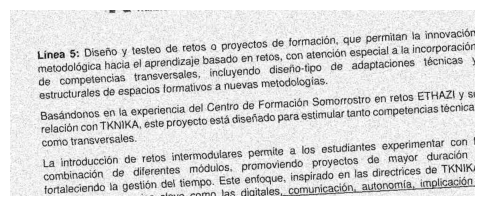

In [17]:
worse = scan(Image.open(images[3]), angle=3, noise=40, quality=15)

if worse is not None:
    text = "\n".join(rapid(np.array(worse)).txts or [])
    print(f"CER {cer(digital[3], text):.3f} | F1 {word_f1(digital[3], text):.3f}")
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.imshow(worse.crop((100, 150, 1100, 550)))
    ax.axis("off")
    plt.show()
else:
    print("Completa el TODO: crea el escaneo peor.")

In [18]:
from rag_lab import models

models.release()

## Qué hemos visto

- Un PDF escaneado no tiene capa de texto: sin OCR, el RAG no tiene nada que indexar.
- RapidOCR detecta líneas y las lee, pero no entiende la estructura; Docling añade el análisis de la maquetación y
  devuelve tablas; un VLM lee la página entera y devuelve la estructura que le pidamos.
- CER y WER dependen del orden de lectura; el F1 de palabras no. Hay que elegir la métrica según el documento.
- Un VLM puede inventarse texto cuando la imagen es mala, y el texto inventado parece correcto: su salida hay que
  validarla.

## Ejercicio propuesto

Imprime la página 13 del PDF, hazle una foto con el móvil y pásala por los tres motores, con el texto del PDF
digital como referencia. ¿Qué motor aguanta mejor una foto real (sombras, perspectiva) que el escaneo simulado?